# Marine radar segmentation: pooled sources, three U-Net encoders

Run cells in order on Google Colab with a GPU runtime. The notebook uses the existing `train`, `val`, `test` folders from every discovered representation branch, pooling their training images into one training loader. It does **not** turn mask files into input images. A source audit and image–mask checks run before training. The test set is evaluated once, after model selection on validation data.

**Important:** The current folder inventory has five visible representation branches, not six verified radar identities. Check the printed filename/source audit with your professor. Similar frames or Cartesian/polar conversions of the same acquisition must stay within the same split; this notebook detects filename matches and reports them, but cannot infer undocumented acquisition IDs.

In [1]:
!pip -q install segmentation-models-pytorch==0.5.0

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 154.8/154.8 kB 5.5 MB/s eta 0:00:00


## 1. Discover branches and pair masks

Only folders with a corresponding annotation folder are loaded. Pairs are matched by filename after stripping the leading `gt_` from a mask name. An unmatched or ambiguous pair raises an error; inspect the reported names and adapt `mask_key` if your dataset uses a different naming rule.

In [8]:
from google.colab import drive
drive.mount('/content/drive')
from pathlib import Path
import os, re, json, random, time, csv, shutil
from collections import Counter, defaultdict
import numpy as np
from PIL import Image
import matplotlib.pyplot as plt
import torch
from torch.utils.data import Dataset, DataLoader
import torch.nn.functional as F
import segmentation_models_pytorch as smp
from tqdm.auto import tqdm

ROOT = Path('/content/drive/MyDrive/Radar Dataset')
OUT = Path('/content/drive/MyDrive/radar_unet_results')
OUT.mkdir(parents=True, exist_ok=True)
SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
if torch.cuda.is_available(): torch.cuda.manual_seed_all(SEED)
torch.backends.cudnn.benchmark = True
DEVICE = 'cuda' if torch.cuda.is_available() else 'cpu'
print('device:', DEVICE, 'dataset exists:', ROOT.is_dir())
assert ROOT.is_dir(), 'Change ROOT to the actual Google Drive dataset location.'

Mounted at /content/drive
device: cuda dataset exists: True


In [9]:
EXTS={'.png','.jpg','.jpeg','.tif','.tiff','.bmp'}
SPLITS=('train','val','test')
def files_in(path):
    return sorted((x for x in path.iterdir() if x.is_file() and x.suffix.lower() in EXTS), key=lambda x:x.name)
def mask_key(p):
    stem=p.stem
    if stem.lower().startswith('gt_'): stem=stem[3:]
    return stem.lower()

def branch_name(parent):
    return str(parent.relative_to(ROOT))

branches=[]
for parent in sorted(ROOT.rglob('*')):
    if parent.is_dir() and all((parent/s).is_dir() and (parent/(s+'annot')).is_dir() for s in SPLITS):
        branches.append(parent)
assert branches, 'No branches with train/trainannot, val/valannot, test/testannot found.'
rows=[]
for parent in branches:
    for split in SPLITS:
        images=files_in(parent/split); masks=files_in(parent/(split+'annot'))
        image_by=defaultdict(list); mask_by=defaultdict(list)
        for x in images: image_by[x.stem.lower()].append(x)
        for x in masks: mask_by[mask_key(x)].append(x)
        missing_img=set(mask_by)-set(image_by); missing_mask=set(image_by)-set(mask_by)
        ambiguous=[k for k,v in image_by.items() if len(v)>1]+[k for k,v in mask_by.items() if len(v)>1]
        if missing_img or missing_mask or ambiguous:
            print('PAIRING ERROR:',branch_name(parent),split)
            print('masks without images:',sorted(missing_img)[:15])
            print('images without masks:',sorted(missing_mask)[:15])
            print('ambiguous:',ambiguous[:15])
            raise ValueError('Fix filename pairing before training; never pair by sorted position.')
        for key in sorted(image_by):
            rows.append(dict(branch=branch_name(parent), split=split,
                             rep='POLAR' if 'POLAR' in parent.parts else 'CARTESIAN',
                             key=key,image=str(image_by[key][0]),mask=str(mask_by[key][0])))
print('Branches:',len(branches))
for parent in branches:
    name=branch_name(parent)
    print(name, {s:sum(r['branch']==name and r['split']==s for r in rows) for s in SPLITS})
print('Paired images:',len(rows),'split:',dict(Counter(r['split'] for r in rows)))
assert len(rows)==3360, 'Counts differ from the earlier audit; inspect the discovered branches.'
with open(OUT/'paired_manifest.csv','w',newline='') as f:
    w=csv.DictWriter(f,fieldnames=rows[0].keys());w.writeheader();w.writerows(rows)

Branches: 5
CARTESIAN {'train': 1800, 'val': 300, 'test': 300}
TEST_45359_RADAR_1_LABEL/CARTESIAN {'train': 180, 'val': 30, 'test': 30}
TEST_45359_RADAR_1_LABEL/POLAR {'train': 180, 'val': 30, 'test': 30}
TEST_62517_RADAR_LABEL/CARTESIAN {'train': 180, 'val': 30, 'test': 30}
TEST_62517_RADAR_LABEL/POLAR {'train': 180, 'val': 30, 'test': 30}
Paired images: 3360 split: {'train': 2520, 'val': 420, 'test': 420}


In [5]:
# Look for source/radar identifiers in filenames and overlaps among splits.
for branch in sorted(set(r['branch'] for r in rows)):
    sample=[Path(r['image']).name for r in rows if r['branch']==branch][:12]
    print('\nBRANCH',branch,'sample filenames:',sample)
for split in SPLITS:
    print(split,Counter(r['branch'] for r in rows if r['split']==split))
# This is a useful warning, not a proof of independence: different names can refer to nearby frames.
for a,b in [('train','val'),('train','test'),('val','test')]:
    ka={r['key'] for r in rows if r['split']==a};kb={r['key'] for r in rows if r['split']==b}
    print('Same basename across',a,b,':',len(ka&kb),'examples:',sorted(ka&kb)[:8])
print('Check acquisition IDs and time adjacency manually before interpreting held-out results.')


BRANCH CARTESIAN sample filenames: ['bssh_0000_2.png', 'bssh_0000_3.png', 'bssh_0000_6.png', 'bssh_0000_7.png', 'bssh_0004_2.png', 'bssh_0004_3.png', 'bssh_0004_5.png', 'bssh_0004_6.png', 'bssh_0006_1.png', 'bssh_0006_3.png', 'bssh_0006_5.png', 'bssh_0006_6.png']

BRANCH TEST_45359_RADAR_1_LABEL/CARTESIAN sample filenames: ['jg_45359.70_1.png', 'jg_45359.70_2.png', 'jg_45359.70_3.png', 'jg_45359.70_4.png', 'jg_45359.70_5.png', 'jg_45359.70_6.png', 'jg_45359.70_7.png', 'jg_45400.90_1.png', 'jg_45400.90_5.png', 'jg_45400.90_7.png', 'jg_45401.40_1.png', 'jg_45401.40_2.png']

BRANCH TEST_45359_RADAR_1_LABEL/POLAR sample filenames: ['jg_45359.70_1.png', 'jg_45359.70_2.png', 'jg_45359.70_3.png', 'jg_45359.70_4.png', 'jg_45359.70_5.png', 'jg_45359.70_6.png', 'jg_45359.70_7.png', 'jg_45400.90_1.png', 'jg_45400.90_5.png', 'jg_45400.90_7.png', 'jg_45401.40_1.png', 'jg_45401.40_2.png']

BRANCH TEST_62517_RADAR_LABEL/CARTESIAN sample filenames: ['jg_62529.00_1.png', 'jg_62529.00_2.png', 'jg_62529

## 2. Inspect exact annotation colors

The next cell scans every original mask and records RGB colors. This may take a few minutes. It preserves indexed PNG palette colors and never interpolates class labels. If masks are grayscale values rather than RGB classes, edit `normalize_mask_colors` after inspecting the sample panel.

CARTESIAN train image (947, 947, 3) mask (947, 947, 3) mask sample colors: [[0, 0, 0], [0, 0, 255], [0, 255, 0], [255, 0, 0]]
CARTESIAN train image (947, 947, 3) mask (947, 947, 3) mask sample colors: [[0, 0, 0], [0, 0, 255], [0, 255, 0], [255, 0, 0]]
TEST_62517_RADAR_LABEL/POLAR test image (947, 947, 3) mask (947, 947, 3) mask sample colors: [[0, 0, 0], [0, 0, 255], [0, 255, 0], [255, 0, 0]]


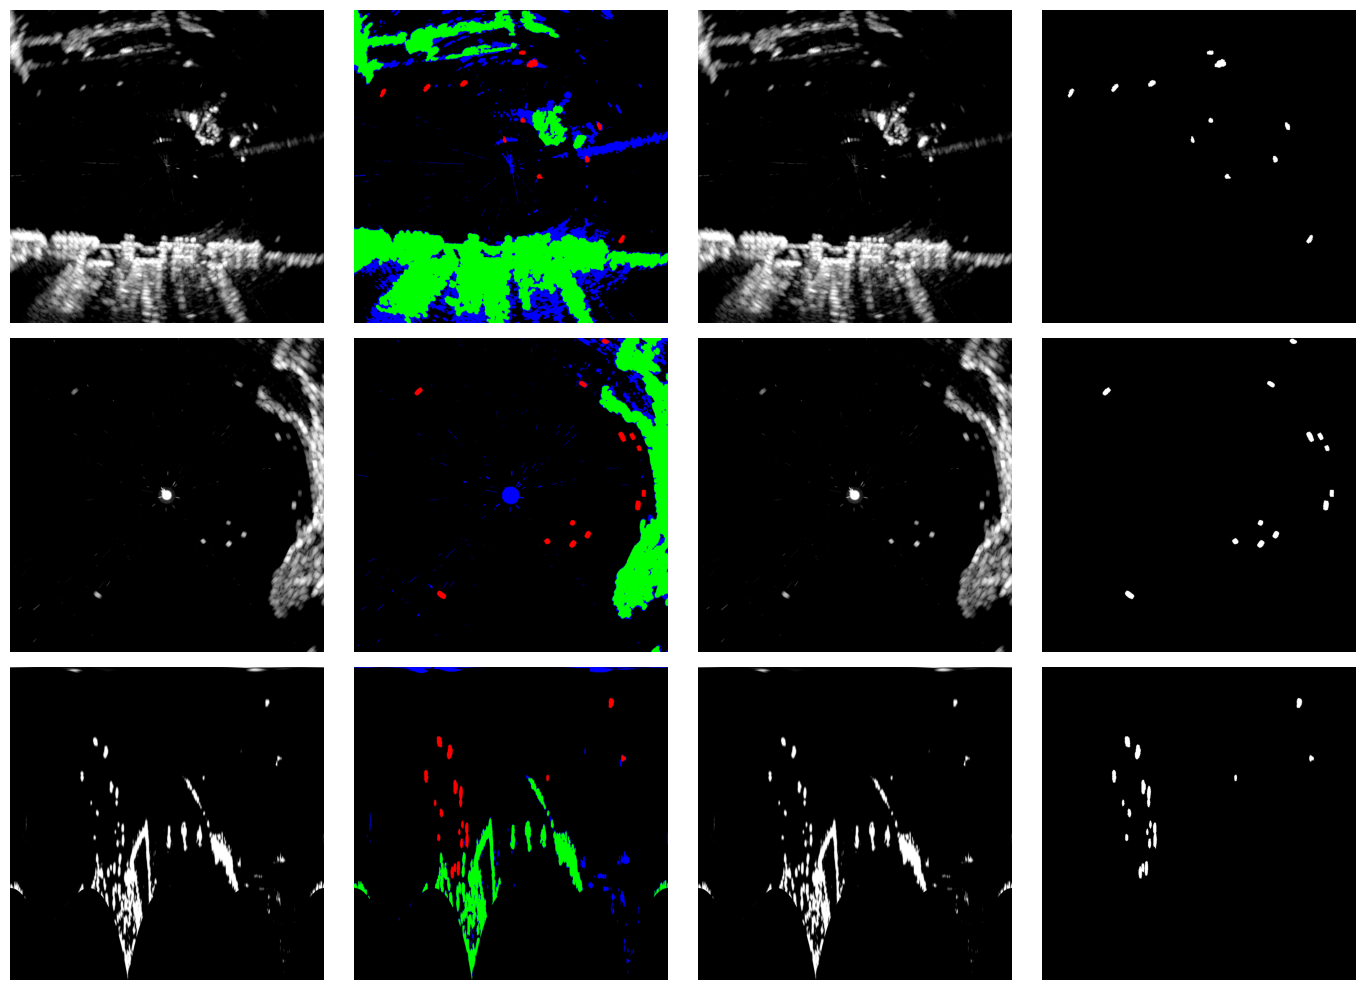

In [6]:
def read_image(path):
    with Image.open(path) as im: return np.asarray(im.convert('RGB'))
def read_mask_rgb(path):
    with Image.open(path) as im: return np.asarray(im.convert('RGB'))
fig,axes=plt.subplots(3,4,figsize=(14,10))
for i,r in enumerate([rows[0],rows[len(rows)//2],rows[-1]]):
    x=read_image(r['image']); y=read_mask_rgb(r['mask'])
    print(r['branch'],r['split'],'image',x.shape,'mask',y.shape,'mask sample colors:',
          np.unique(y.reshape(-1,3)[::max(1,len(y.reshape(-1,3))//20000)],axis=0)[:20].tolist())
    axes[i,0].imshow(x);axes[i,1].imshow(y)
    axes[i,2].imshow(x[:,:,0],cmap='gray');axes[i,3].imshow(y[:,:,0],cmap='gray')
    for j in range(4): axes[i,j].axis('off')
plt.tight_layout();plt.show()

In [7]:
# def pack(rgb):
#     a=rgb.astype(np.uint32)
#     return (a[...,0]<<16)|(a[...,1]<<8)|a[...,2]
# def unpack(k): return [int((k>>16)&255),int((k>>8)&255),int(k&255)]
# palette_counts=Counter()
# for r in tqdm(rows,desc='Scanning original mask colors'):
#     x=read_mask_rgb(r['mask'])
#     u,n=np.unique(pack(x),return_counts=True)
#     palette_counts.update({int(k):int(v) for k,v in zip(u,n)})
#     if len(palette_counts)>32:
#         raise ValueError('More than 32 mask colors. Masks may have antialiasing or continuous values. Inspect labels; do not automatically treat each shade as a class.')
# print('Mask colors (RGB, pixels):',[(unpack(k),v) for k,v in palette_counts.most_common()])
# assert len(palette_counts)>=2, 'Only one mask color found; inspect annotations.'
# # Explicit semantic colors; the 13 low-count neutral gray colors are likely rendering artifacts.
# PALETTE=[0x000000,0x00ff00,0x0000ff,0xff0000]
# EXTRA_COLORS=set(palette_counts)-set(PALETTE)
# NEUTRAL_ARTIFACTS={k for k in EXTRA_COLORS if (k>>16)==((k>>8)&255)==(k&255)}
# other=EXTRA_COLORS-NEUTRAL_ARTIFACTS
# assert not other, 'Unexpected non-gray mask colors: '+str([unpack(k) for k in sorted(other)])
# neutral_pixels=sum(palette_counts[k] for k in NEUTRAL_ARTIFACTS)
# neutral_fraction=neutral_pixels/sum(palette_counts.values())
# print('Rare neutral-gray pixels:',neutral_pixels,'fraction:',neutral_fraction)
# assert neutral_fraction<0.0001, 'Gray pixels are too frequent; inspect masks before mapping them to background.'
# print('Class ID -> RGB:',{i:unpack(k) for i,k in enumerate(PALETTE)})
# print('Mapping these gray RGB values to background:',[unpack(k) for k in sorted(NEUTRAL_ARTIFACTS)])
# NUM_CLASSES=len(PALETTE)
# with open(OUT/'palette.json','w') as f:
#     json.dump(dict(classes={str(i):unpack(k) for i,k in enumerate(PALETTE)},
#                    mapped_to_background=[unpack(k) for k in sorted(NEUTRAL_ARTIFACTS)]),f,indent=2)

Check the class mapping above: black is assigned class 0, green 1, blue 2, and red 3. The 13 rare neutral-gray shades are provisionally mapped to background. Inspect their locations on a few masks before publication; if they represent a real class, change the mapping. Pixel metrics are computed per class; the average excludes class 0.

In [8]:
# def mask_to_ids(rgb):
#     packed=pack(rgb)
#     ids=np.full(packed.shape,255,np.uint8)
#     for i,color in enumerate(PALETTE): ids[packed==color]=i
#     for color in NEUTRAL_ARTIFACTS: ids[packed==color]=0
#     if np.any(ids==255):
#         unexpected=np.unique(packed[ids==255])[:10]
#         raise ValueError('Unexpected mask colors: '+str([unpack(int(k)) for k in unexpected]))
#     return ids
# # Check input/mask dimensions and detect duplicate exact image files across splits.
# from hashlib import sha256
# for r in tqdm(rows,desc='Checking dimensions'):
#     with Image.open(r['image']) as x, Image.open(r['mask']) as y:
#         if x.size!=y.size: raise ValueError(f"Dimension mismatch: {r['image']} {r['mask']} {x.size} {y.size}")
# print('All pairs have matching original dimensions.')

In [5]:
import numpy as np

def pack(rgb):
    a = rgb.astype(np.uint32)
    return (a[..., 0] << 16) | (a[..., 1] << 8) | a[..., 2]

def unpack(k):
    return [int((k >> 16) & 255), int((k >> 8) & 255), int(k & 255)]

# Background, green, blue, red
PALETTE = [0x000000, 0x00FF00, 0x0000FF, 0xFF0000]
NUM_CLASSES = 4

# The 13 rare grayscale shades found in your completed scan
NEUTRAL_ARTIFACTS = {
    (v << 16) | (v << 8) | v
    for v in [34, 51, 68, 85, 102, 119, 136,
              153, 170, 187, 204, 221, 238]
}

def mask_to_ids(rgb):
    packed = pack(rgb)
    ids = np.full(packed.shape, 255, dtype=np.uint8)

    for class_id, color in enumerate(PALETTE):
        ids[packed == color] = class_id

    for color in NEUTRAL_ARTIFACTS:
        ids[packed == color] = 0

    if np.any(ids == 255):
        unknown = np.unique(packed[ids == 255])[:10]
        raise ValueError(
            f"Unexpected mask colors: {[unpack(int(k)) for k in unknown]}"
        )
    return ids

print("NUM_CLASSES =", NUM_CLASSES)
print("Mask converter is ready")

NUM_CLASSES = 4
Mask converter is ready


## 3. Data loader and models

Use a common image size and augmentation policy for all three models. Input images are converted to RGB so ImageNet weights can be used. This does not create new radar information. Masks are resized with nearest-neighbor interpolation. For polar frames, only modest brightness and horizontal shifts are used here; geometric flips or arbitrary rotations could change the meaning of bearing/range.

In [10]:
from torchvision.transforms import functional as TF
IMAGE_SIZE=(512,512) # lower to (384,384) if GPU memory is insufficient
BATCH_SIZE=8
NUM_WORKERS=2
EPOCHS=20
PATIENCE=5
LR=2e-4
USE_IMAGENET=True
# Change to None to use all discovered representation branches in each pooled model.
# 'CARTESIAN' and 'POLAR' run separate representation experiments.
REPRESENTATION_RUNS=['ALL']

class RadarDataset(Dataset):
    def __init__(self, items, train=False): self.items=items; self.train=train
    def __len__(self): return len(self.items)
    def __getitem__(self,i):
        r=self.items[i]
        with Image.open(r['image']) as im:
            x=im.convert('RGB').resize(IMAGE_SIZE[::-1],Image.Resampling.BILINEAR)
            x=np.array(x,copy=True)
        with Image.open(r['mask']) as im:
            y=im.convert('RGB').resize(IMAGE_SIZE[::-1],Image.Resampling.NEAREST)
            y=mask_to_ids(np.asarray(y))
        x=torch.from_numpy(np.ascontiguousarray(x)).permute(2,0,1).float()/255.
        y=torch.from_numpy(np.ascontiguousarray(y)).long()
        if self.train:
            # Apply spatial changes jointly. No random flips, rotations or range shifts by default.
            if random.random()<0.5:
                x=(x*random.uniform(.85,1.15)).clamp(0,1)
        x=TF.normalize(x,mean=[.485,.456,.406],std=[.229,.224,.225]) if USE_IMAGENET else x
        return x,y

def subset(rep,split):
    return [r for r in rows if r['split']==split and (rep=='ALL' or r['rep']==rep)]
def loaders(rep):
    return {s:DataLoader(RadarDataset(subset(rep,s),train=(s=='train')),
            batch_size=BATCH_SIZE,shuffle=(s=='train'),num_workers=NUM_WORKERS,
            pin_memory=(DEVICE=='cuda'),persistent_workers=(NUM_WORKERS>0)) for s in SPLITS}

class BasicUNet(torch.nn.Module):
    def __init__(self,k):
        super().__init__()
        def block(a,b): return torch.nn.Sequential(torch.nn.Conv2d(a,b,3,padding=1),torch.nn.BatchNorm2d(b),torch.nn.ReLU(inplace=True),torch.nn.Conv2d(b,b,3,padding=1),torch.nn.BatchNorm2d(b),torch.nn.ReLU(inplace=True))
        self.e1=block(3,32);self.e2=block(32,64);self.e3=block(64,128);self.mid=block(128,256)
        self.d3=block(256+128,128);self.d2=block(128+64,64);self.d1=block(64+32,32)
        self.head=torch.nn.Conv2d(32,k,1)
    def forward(self,x):
        a=self.e1(x);b=self.e2(F.max_pool2d(a,2));c=self.e3(F.max_pool2d(b,2));z=self.mid(F.max_pool2d(c,2))
        z=self.d3(torch.cat([F.interpolate(z,size=c.shape[-2:],mode='bilinear',align_corners=False),c],1))
        z=self.d2(torch.cat([F.interpolate(z,size=b.shape[-2:],mode='bilinear',align_corners=False),b],1))
        z=self.d1(torch.cat([F.interpolate(z,size=a.shape[-2:],mode='bilinear',align_corners=False),a],1))
        return self.head(z)
def make_model(name):
    if name=='custom_unet': return BasicUNet(NUM_CLASSES)
    return smp.Unet(encoder_name=name,encoder_weights='imagenet' if USE_IMAGENET else None,
                    in_channels=3,classes=NUM_CLASSES)
MODELS=['custom_unet','resnet34','efficientnet-b0']
print('models',MODELS,'representation experiments',REPRESENTATION_RUNS)

models ['custom_unet', 'resnet34', 'efficientnet-b0'] representation experiments ['ALL']


## 4. Training and validation

Validation macro Dice excludes class 0 and skips classes absent from the *entire validation set* by default. Precision/recall are aggregated from dataset-wide pixel counts. The loss combines cross-entropy and soft Dice over foreground classes.

In [7]:
def seg_loss(logits,y):
    ce=F.cross_entropy(logits,y)
    probs=logits.softmax(1)
    target=F.one_hot(y,NUM_CLASSES).permute(0,3,1,2).float()
    axes=(0,2,3)
    dice=(2*(probs*target).sum(axes)+1)/((probs+target).sum(axes)+1)
    return ce + (1-dice[1:].mean())

def empty_cm(): return torch.zeros((NUM_CLASSES,NUM_CLASSES),dtype=torch.int64)
def add_cm(cm,pred,target):
    flat=(target.flatten()*NUM_CLASSES+pred.flatten()).to(torch.int64)
    cm+=torch.bincount(flat,minlength=NUM_CLASSES**2).reshape(NUM_CLASSES,NUM_CLASSES).cpu()

def metrics(cm):
    tp=cm.diag().double();support=cm.sum(1).double();predicted=cm.sum(0).double()
    dice=(2*tp/(support+predicted).clamp(min=1)).tolist()
    iou=(tp/(support+predicted-tp).clamp(min=1)).tolist()
    prec=(tp/predicted.clamp(min=1)).tolist();rec=(tp/support.clamp(min=1)).tolist()
    active=[j for j in range(1,NUM_CLASSES) if support[j]>0]
    return dict(dice=float(np.mean([dice[j] for j in active])) if active else 0.,
                iou=float(np.mean([iou[j] for j in active])) if active else 0.,
                precision=float(np.mean([prec[j] for j in active])) if active else 0.,
                recall=float(np.mean([rec[j] for j in active])) if active else 0.,
                per_class={str(j):dict(dice=dice[j],iou=iou[j],precision=prec[j],recall=rec[j],pixels=int(support[j])) for j in range(NUM_CLASSES)})

def evaluate(model,loader):
    model.eval();cm=empty_cm();loss_sum=0.;n=0;seconds=0.
    with torch.inference_mode():
        for x,y in loader:
            x=x.to(DEVICE,non_blocking=True);y=y.to(DEVICE,non_blocking=True)
            if DEVICE=='cuda':torch.cuda.synchronize()
            t=time.perf_counter()
            with torch.autocast(device_type=DEVICE,enabled=DEVICE=='cuda'):
                logits=model(x);loss=seg_loss(logits,y)
            if DEVICE=='cuda':torch.cuda.synchronize()
            seconds+=time.perf_counter()-t
            add_cm(cm,logits.argmax(1),y);loss_sum+=loss.item()*len(x);n+=len(x)
    return dict(loss=loss_sum/n,**metrics(cm),ms_per_image=1000*seconds/n),cm

def train_one(model_name,rep):
    ls=loaders(rep); model=make_model(model_name).to(DEVICE)
    optimizer=torch.optim.AdamW(model.parameters(),lr=LR,weight_decay=1e-4)
    scaler=torch.amp.GradScaler('cuda',enabled=DEVICE=='cuda')
    best=-1.;wait=0;run=OUT/f'{rep}_{model_name}';run.mkdir(exist_ok=True)
    history=[]
    for epoch in range(1,EPOCHS+1):
        model.train();total=0.;count=0
        for x,y in tqdm(ls['train'],desc=f'{rep} {model_name} {epoch}/{EPOCHS}',leave=False):
            x=x.to(DEVICE,non_blocking=True);y=y.to(DEVICE,non_blocking=True)
            optimizer.zero_grad(set_to_none=True)
            with torch.autocast(device_type=DEVICE,enabled=DEVICE=='cuda'):
                logits=model(x);loss=seg_loss(logits,y)
            scaler.scale(loss).backward();scaler.step(optimizer);scaler.update()
            total+=loss.item()*len(x);count+=len(x)
        val,_=evaluate(model,ls['val'])
        record=dict(epoch=epoch,train_loss=total/count,**{('val_'+k):v for k,v in val.items() if k!='per_class'})
        history.append(record);print(rep,model_name,record)
        if val['dice']>best+1e-5:
            best=val['dice'];wait=0
            torch.save(dict(state=model.state_dict(),model_name=model_name,rep=rep,
                            num_classes=NUM_CLASSES,palette=PALETTE,image_size=IMAGE_SIZE,
                            epoch=epoch,val=val),run/'best.pt')
        else:
            wait+=1
            if wait>=PATIENCE: print('Early stopping');break
    with open(run/'history.json','w') as f:json.dump(history,f,indent=2)
    del model;torch.cuda.empty_cache()
    return dict(rep=rep,model=model_name,best_val_dice=best,checkpoint=str(run/'best.pt'))

In [12]:
REPRESENTATION_RUNS = ["ALL"]
MODELS = ["custom_unet", "resnet34", "efficientnet-b0"]
SPLITS = ("train", "val", "test")

# These functions must be defined by the preceding notebook cells.
assert callable(subset), "Run the Data loader and models cell first."
assert callable(train_one), "Run the loss and training functions cell first."

completed = []

for rep in REPRESENTATION_RUNS:
    counts = {split: len(subset(rep, split)) for split in SPLITS}
    assert all(counts.values()), f"Missing data: {counts}"
    print(f"Starting {rep}: {counts}")

    for model_name in MODELS:
        result = train_one(model_name, rep)
        completed.append(result)
        print("Finished:", result)

print("Completed experiments:", completed)

Starting ALL: {'train': 2520, 'val': 420, 'test': 420}


ALL custom_unet 1/20:   0%|          | 0/315 [00:00<?, ?it/s]

ALL custom_unet {'epoch': 1, 'train_loss': 1.3665242696565294, 'val_loss': 1.0780594791684832, 'val_dice': 0.8284727695543701, 'val_iou': 0.7193268749914566, 'val_precision': 0.8051130866512702, 'val_recall': 0.8542596482277394, 'val_ms_per_image': 21.02428263808958}


ALL custom_unet 2/20:   0%|          | 0/315 [00:00<?, ?it/s]

ALL custom_unet {'epoch': 2, 'train_loss': 0.7589381361764574, 'val_loss': 0.6520213649386452, 'val_dice': 0.8388999317885624, 'val_iou': 0.7336385165387879, 'val_precision': 0.8507778585151006, 'val_recall': 0.8372342792118896, 'val_ms_per_image': 16.151533095241923}


ALL custom_unet 3/20:   0%|          | 0/315 [00:00<?, ?it/s]

... (95 outputs left out)

ALL efficientnet-b0 19/20:   0%|          | 0/315 [00:00<?, ?it/s]

ALL efficientnet-b0 {'epoch': 19, 'train_loss': 0.1118929109876118, 'val_loss': 0.13729506986481801, 'val_dice': 0.922767008659329, 'val_iou': 0.8604618907211741, 'val_precision': 0.9317568998272764, 'val_recall': 0.914055209978181, 'val_ms_per_image': 9.604514114298148}


ALL efficientnet-b0 20/20:   0%|          | 0/315 [00:00<?, ?it/s]

ALL efficientnet-b0 {'epoch': 20, 'train_loss': 0.10944000991090895, 'val_loss': 0.13417109605811892, 'val_dice': 0.9242682707196336, 'val_iou': 0.8626045591133294, 'val_precision': 0.91685559875474, 'val_recall': 0.9321347887246126, 'val_ms_per_image': 9.9991987047577}
Finished: {'rep': 'ALL', 'model': 'efficientnet-b0', 'best_val_dice': 0.9251864620816589, 'checkpoint': '/content/drive/MyDrive/radar_unet_results/ALL_efficientnet-b0/best.pt'}
Completed experiments: [{'rep': 'ALL', 'model': 'custom_unet', 'best_val_dice': 0.8879290037245336, 'checkpoint': '/content/drive/MyDrive/radar_unet_results/ALL_custom_unet/best.pt'}, {'rep': 'ALL', 'model': 'resnet34', 'best_val_dice': 0.9196622933669772, 'checkpoint': '/content/drive/MyDrive/radar_unet_results/ALL_resnet34/best.pt'}, {'rep': 'ALL', 'model': 'efficientnet-b0', 'best_val_dice': 0.9251864620816589, 'checkpoint': '/content/drive/MyDrive/radar_unet_results/ALL_efficientnet-b0/best.pt'}]


## 5. Single final test evaluation and visual examples

Run once after finishing all validation comparisons. If the final goal is one deployed model, choose the highest validation Dice among pooled models; keep every per-model test result for your benchmark report.

In [13]:
completed = []

for checkpoint in sorted(OUT.glob("ALL_*/best.pt")):
    ck = torch.load(checkpoint, map_location="cpu", weights_only=False)
    completed.append({
        "rep": ck["rep"],
        "model": ck["model_name"],
        "best_val_dice": ck["val"]["dice"],
        "checkpoint": str(checkpoint),
    })

print(f"Recovered {len(completed)} trained models:")
for item in completed:
    print(item["model"], "validation Dice:", item["best_val_dice"])

assert completed, "No saved checkpoints found. The training loop must finish at least one epoch first."

Recovered 3 trained models:
custom_unet validation Dice: 0.8879290037245336
efficientnet-b0 validation Dice: 0.9251864620816589
resnet34 validation Dice: 0.9196622933669772


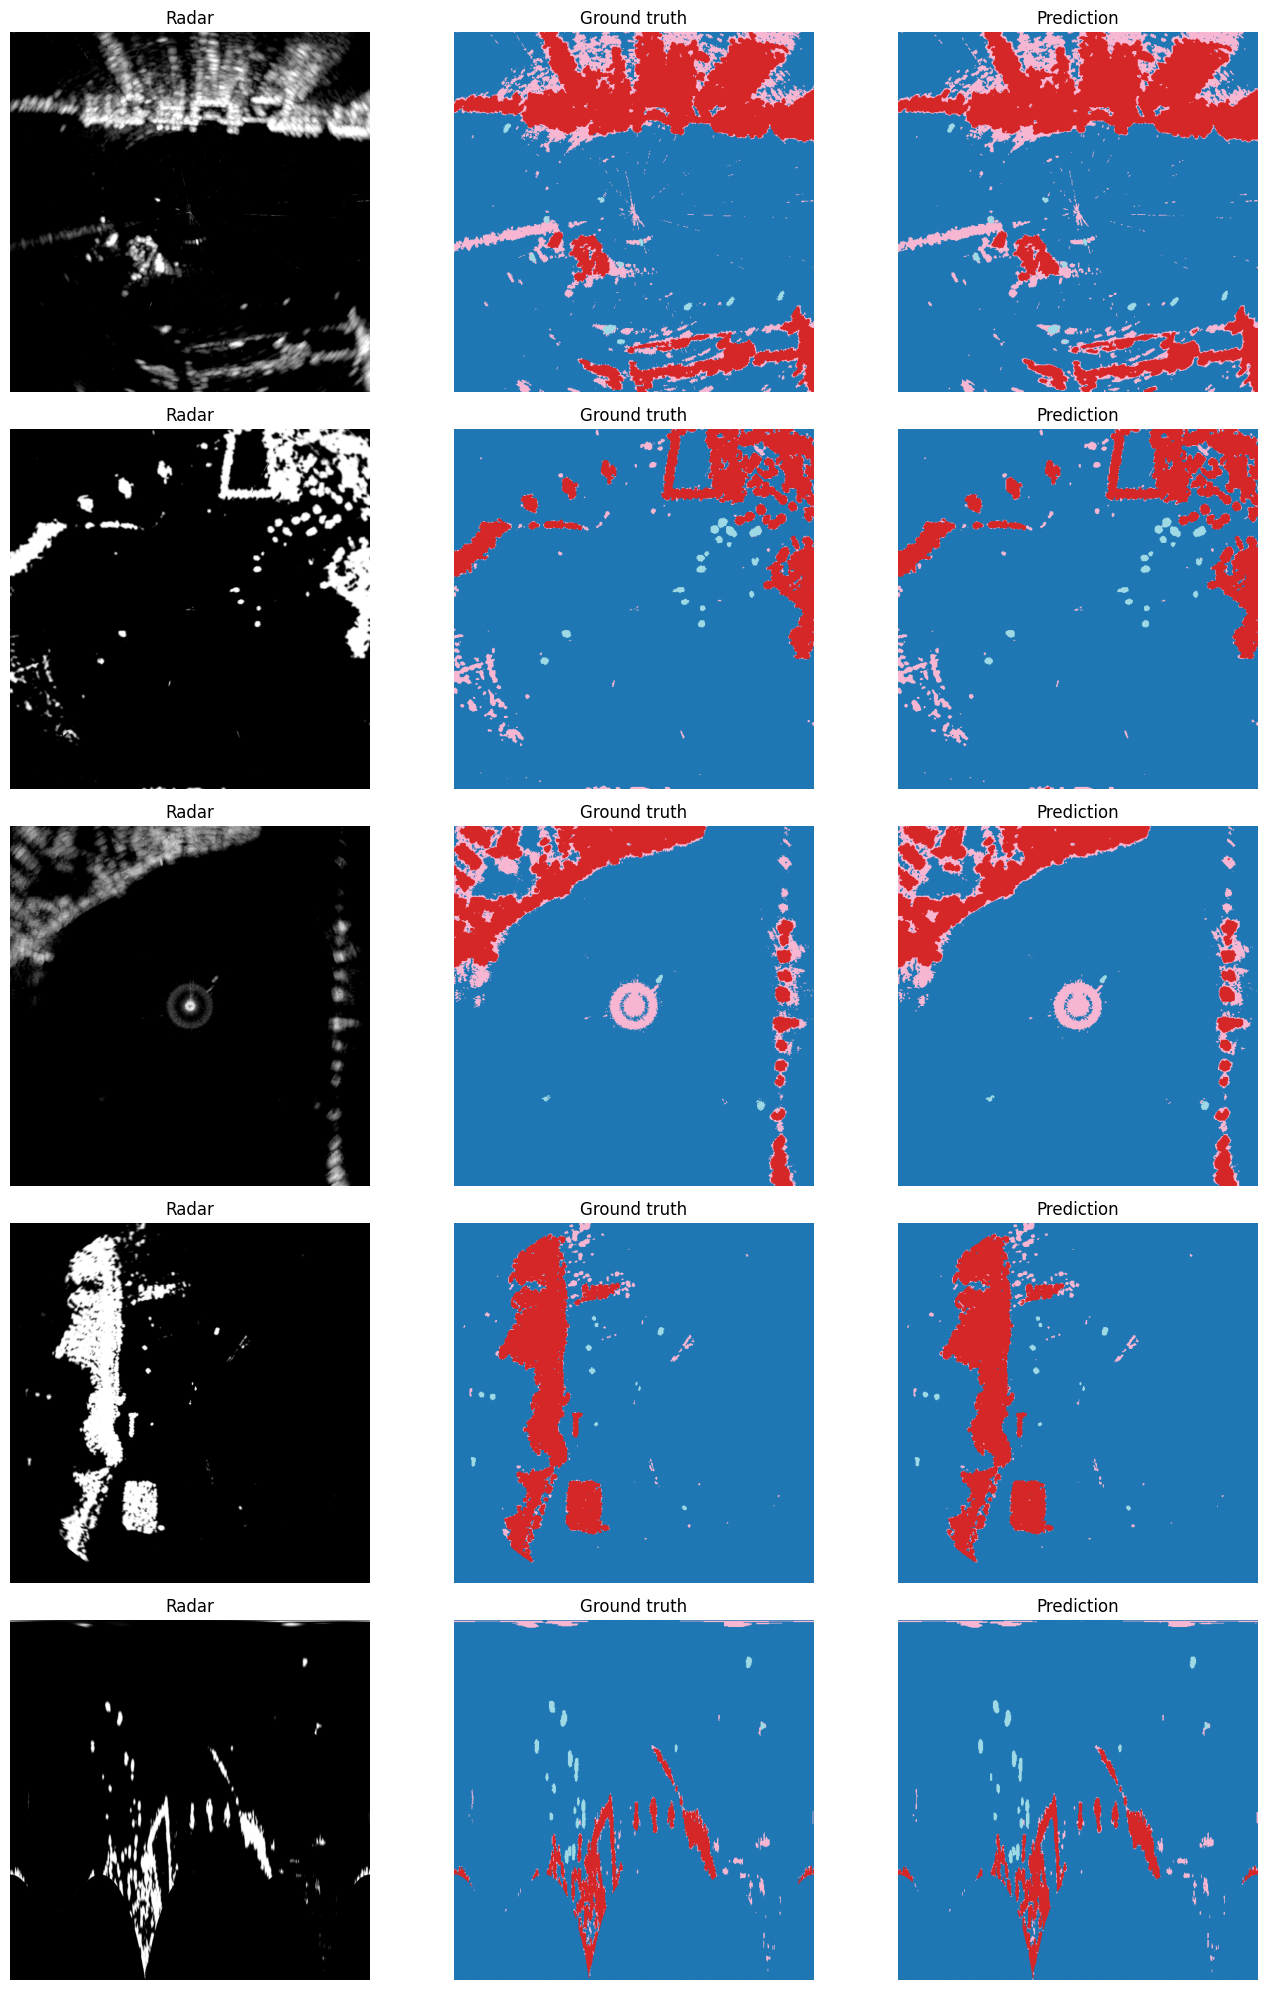

In [14]:
# Visual quality check for the best pooled model (selection based on validation only).
choice=max((r for r in completed if r['rep']=='ALL'),key=lambda x:x['best_val_dice'])
model=make_model(choice['model']).to(DEVICE)
model.load_state_dict(torch.load(choice['checkpoint'],map_location='cpu',weights_only=False)['state'])
model.eval()
examples=subset('ALL','test')
chosen=[examples[i] for i in np.linspace(0,len(examples)-1,min(5,len(examples)),dtype=int)]
fig,axes=plt.subplots(len(chosen),3,figsize=(14,4*len(chosen)),squeeze=False)
for i,r in enumerate(chosen):
    ds=RadarDataset([r]);x,y=ds[0]
    with torch.inference_mode(),torch.autocast(device_type=DEVICE,enabled=DEVICE=='cuda'):
        pred=model(x[None].to(DEVICE)).argmax(1).squeeze(0).cpu().numpy()
    axes[i,0].imshow(read_image(r['image']));axes[i,1].imshow(y,cmap='tab20',vmin=0,vmax=NUM_CLASSES-1)
    axes[i,2].imshow(pred,cmap='tab20',vmin=0,vmax=NUM_CLASSES-1)
    axes[i,0].set_ylabel(r['branch']+'\n'+Path(r['image']).name)
    for j,title in enumerate(['Radar','Ground truth','Prediction']):
        axes[i,j].set_title(title);axes[i,j].axis('off')
plt.tight_layout();plt.savefig(OUT/'prediction_examples.png',dpi=140,bbox_inches='tight');plt.show()

## Interpretation and next improvement

The pooled ALL experiment uses **2,520 training**, **420 validation**, and **420 test** image–mask pairs according to the supplied inventory. Cartesian-only should have 2,160/360/360 and polar-only 360/60/60, subject to the pairing audit. Counts do not establish six distinct radar IDs. For a rigorous follow-up, add an acquisition/radar ID to the manifest and report performance separately per source. Existing random-looking splits may contain near-adjacent frames, so verify independence before publication.

The first improvement is a *balanced sampler by branch* (or source ID, once verified), as the large Cartesian branch dominates pooled training. Then compare the same three models at equal resolution, epochs, and validation protocol. Try larger resolution only if small radar targets are lost at 512 pixels. Do not tune on the test set.